# B5: Rangkaian Praproses SIMUTEH
SIMUTEH | SEED = 1013 | NIM 2330511013

In [1]:
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak
from praproses import praproses, simpan_param
D = "../data/sintetis"
KANAL = 2                  # kanal terbaik dari Bagian 2: R (indeks BGR: 2)
label = pd.read_csv(f"{D}/label.csv")
urut = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
def muat(nm):
    return (baca(f"{D}/citra/{nm}"), cv2.imread(f"{D}/mask_daun/{nm}", 0),
            cv2.imread(f"{D}/mask_bercak/{nm}", 0))
berbercak = label[label.kelas != "sehat"]
print(len(berbercak), "citra berbercak (ringan + berat)")

40 citra berbercak (ringan + berat)


## Pemilihan parameter: uji beberapa kombinasi pada 40 citra berbercak

In [2]:
kombinasi = {}
for clip in [0, 2.0, 4.0]:
    for pen, ker in [("none", 1), ("median", 3), ("median", 5), ("rerata", 5)]:
        for tj in [0.0, 0.5]:
            kombinasi[f"clip={clip} {pen}{ker} tajam={tj}"] = {
                "gamma": 1.0, "clahe_clip": clip, "penapis": pen, "kernel": ker, "tajam_k": tj}
data = [muat(nm) for nm in berbercak.nama_file]
baris = []
for nama_k, p in kombinasi.items():
    kb = [kontras_bercak(praproses(im, p)[:, :, KANAL], md, mb) for im, md, mb in data]
    sebelum = [kontras_bercak(im[:, :, KANAL], md, mb) for im, md, mb in data]
    df = pd.DataFrame({"kondisi": berbercak.kondisi_cahaya.values, "sebelum": sebelum, "sesudah": kb})
    g = df.groupby("kondisi").mean().loc[urut]
    baris.append([nama_k, g.sesudah.mean(), g.sesudah.min(),
                  (g.sesudah / g.sebelum - 1).mean() * 100])
grid = pd.DataFrame(baris, columns=["parameter", "KB_rerata", "KB_kondisi_terburuk", "perubahan_%"]).round(2)
print(grid.sort_values("KB_rerata", ascending=False).to_string(index=False))
grid.to_csv("../hasil/b5_pemilihan_parameter.csv", index=False)

                 parameter  KB_rerata  KB_kondisi_terburuk  perubahan_%
  clip=0 median5 tajam=0.5      13.18                 7.29        93.37
  clip=0 median5 tajam=0.0      12.61                 7.11        88.59
  clip=0 median3 tajam=0.0      11.23                 7.14        65.97
  clip=0 median3 tajam=0.5      10.66                 6.46        55.43
clip=2.0 median5 tajam=0.5      10.06                 5.30        42.96
clip=2.0 median5 tajam=0.0       9.98                 5.48        42.87
  clip=0 rerata5 tajam=0.5       9.81                 6.53        54.25
  clip=0 rerata5 tajam=0.0       9.73                 6.43        54.12
clip=2.0 median3 tajam=0.0       9.06                 4.85        30.12
clip=2.0 rerata5 tajam=0.5       8.60                 5.54        27.90
clip=2.0 rerata5 tajam=0.0       8.57                 5.63        27.79
clip=2.0 median3 tajam=0.5       8.50                 4.41        21.81
clip=4.0 median5 tajam=0.0       8.12                 4.00      

## Perbandingan kandidat parameter per kondisi (dasar keputusan)

In [3]:
sehat = label[label.kelas == "sehat"]
data_sehat = [muat(nm) for nm in sehat.nama_file]
kandidat = {
    "tanpa praproses": None,
    "A clip0 median5": {"clahe_clip": 0, "penapis": "median", "kernel": 5},
    "B clip1 tile8 median5": {"clahe_clip": 1.0, "penapis": "median", "kernel": 5},
    "C clip2 tile8 median5": {"clahe_clip": 2.0, "penapis": "median", "kernel": 5},
    "D clip1 tile4 median5": {"clahe_clip": 1.0, "clahe_tile": 4, "penapis": "median", "kernel": 5},
    "E A + tajam0.5": {"clahe_clip": 0, "penapis": "median", "kernel": 5, "tajam_k": 0.5},
}
baris = []
for nm_k, p in kandidat.items():
    ke = lambda im: im if p is None else praproses(im, p)
    kb = [kontras_bercak(ke(im)[:, :, KANAL], md, mb) for im, md, mb in data]
    g = pd.DataFrame({"k": berbercak.kondisi_cahaya.values, "kb": kb}).groupby("k").kb.mean().loc[urut]
    sg = [ke(im)[:, :, KANAL][md > 0].std() for im, md, _ in data_sehat]
    g2 = pd.DataFrame({"k": sehat.kondisi_cahaya.values, "s": sg}).groupby("k").s.mean().loc[urut]
    baris.append([nm_k] + list(g.round(2)) + [round(g.mean(), 2), round(g.min(), 2)] + [round(g2.mean(), 1)])
kolom = ["kandidat"] + ["KB_" + u for u in urut] + ["KB_rerata", "KB_terburuk", "sigma_daun_sehat"]
kand_tabel = pd.DataFrame(baris, columns=kolom)
print(kand_tabel.to_string(index=False))
kand_tabel.to_csv("../hasil/b5_kandidat_parameter.csv", index=False)

             kandidat  KB_normal  KB_gelap  KB_terang  KB_kontras_rendah  KB_bayangan  KB_rerata  KB_terburuk  sigma_daun_sehat
      tanpa praproses       9.51      9.36       6.07               3.63         5.81       6.88         3.63              12.0
      A clip0 median5      16.30     18.70      11.47               9.46         7.11      12.61         7.11               6.2
B clip1 tile8 median5      14.53     18.88       8.65               7.37         8.65      11.62         7.37               6.8
C clip2 tile8 median5      11.75     18.02       6.11               5.48         8.53       9.98         5.48               8.5
D clip1 tile4 median5      14.58     18.49       9.12               8.28         8.66      11.82         8.28               6.3
       E A + tajam0.5      17.48     20.57      11.57               8.98         7.29      13.18         7.29               6.1


## Langkah 5.2 Evaluasi kuantitatif (Kode 5.2)

In [4]:
# parameter final: dipilih agar KB kondisi terburuk paling tinggi (kandidat D)
param = {"gamma": 1.0, "clahe_clip": 1.0, "clahe_tile": 4, "penapis": "median", "kernel": 5, "tajam_k": 0.0}
simpan_param(param, "../hasil/param_praproses.json")
baris = []
for _, d in berbercak.iterrows():
    img, md, mb = muat(d.nama_file)
    out = praproses(img, param)
    baris.append([d.kondisi_cahaya, kontras_bercak(img[:, :, KANAL], md, mb),
                  kontras_bercak(out[:, :, KANAL], md, mb)])
evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
t12 = evaluasi.groupby("kondisi").mean().loc[urut]
t12["perubahan_%"] = (t12.KB_sesudah / t12.KB_sebelum - 1) * 100
t12 = t12.round(2); print(t12)
t12.to_csv("../hasil/b5_tabel12.csv")
print("\nSemua kondisi naik?", bool((t12.KB_sesudah > t12.KB_sebelum).all()))
print(open("../hasil/param_praproses.json").read())

                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
normal                9.51       14.58        53.34
gelap                 9.36       18.49        97.52
terang                6.07        9.12        50.11
kontras_rendah        3.63        8.28       127.96
bayangan              5.81        8.66        49.00

Semua kondisi naik? True
{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 1.0,
  "clahe_tile": 4,
  "penapis": "median",
  "kernel": 5,
  "sigma": 1.0,
  "tajam_k": 0.0
}


## Langkah 5.3 Uji bercak palsu pada kelas sehat

                sigma_sebelum  sigma_sesudah  rasio
kondisi                                            
normal                  11.96           6.63   0.55
gelap                   10.38           5.02   0.48
terang                  12.33           7.12   0.58
kontras_rendah          12.10           5.11   0.42
bayangan                13.34           7.76   0.58


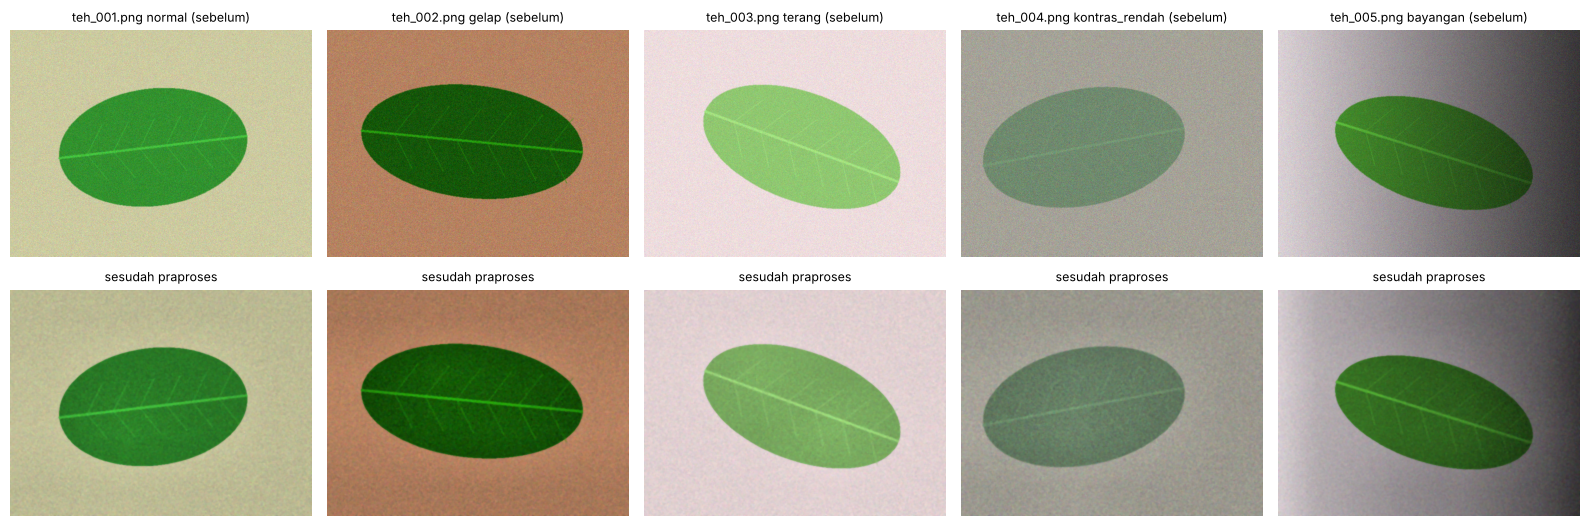

In [5]:
sehat = label[label.kelas == "sehat"]
baris = []
for _, d in sehat.iterrows():
    img, md, _ = muat(d.nama_file)
    out = praproses(img, param)
    daun = md > 0
    baris.append([d.kondisi_cahaya, img[:, :, KANAL][daun].std(), out[:, :, KANAL][daun].std()])
uji = pd.DataFrame(baris, columns=["kondisi", "sigma_sebelum", "sigma_sesudah"])
t53 = uji.groupby("kondisi").mean().loc[urut].round(2)
t53["rasio"] = (t53.sigma_sesudah / t53.sigma_sebelum).round(2)
print(t53); t53.to_csv("../hasil/b5_uji_bercak_palsu.csv")

# panel sebelum dan sesudah: satu citra sehat per kondisi
fig, ax = plt.subplots(2, 5, figsize=(16, 5.5))
for j, kond in enumerate(urut):
    nm = sehat[sehat.kondisi_cahaya == kond].nama_file.iloc[0]
    img, md, _ = muat(nm); out = praproses(img, param)
    ax[0, j].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0, j].set_title(f"{nm} {kond} (sebelum)", fontsize=9)
    ax[1, j].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); ax[1, j].set_title("sesudah praproses", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b5_bercak_palsu_panel.png")

## Contoh hasil praproses pada kelas berat

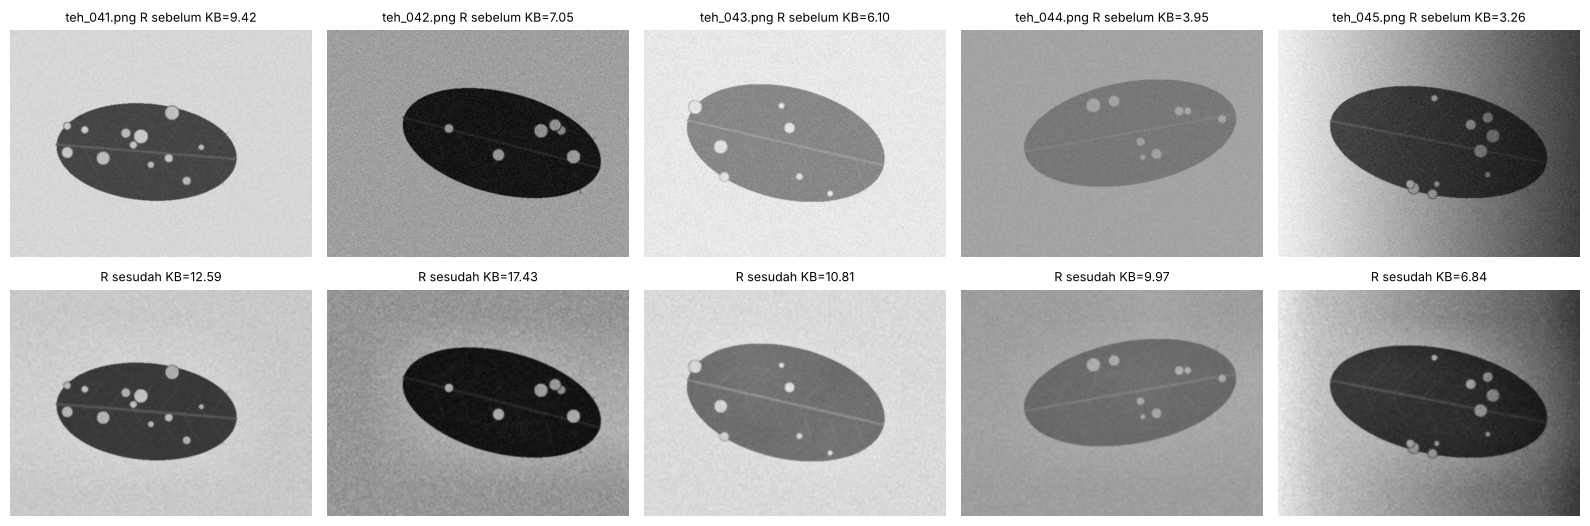

In [6]:
fig, ax = plt.subplots(2, 5, figsize=(16, 5.5))
for j, kond in enumerate(urut):
    nm = berbercak[(berbercak.kelas == "berat") & (berbercak.kondisi_cahaya == kond)].nama_file.iloc[0]
    img, md, mb = muat(nm); out = praproses(img, param)
    ax[0, j].imshow(img[:, :, KANAL], cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(f"{nm} R sebelum KB={kontras_bercak(img[:, :, KANAL], md, mb):.2f}", fontsize=9)
    ax[1, j].imshow(out[:, :, KANAL], cmap="gray", vmin=0, vmax=255); ax[1, j].set_title(f"R sesudah KB={kontras_bercak(out[:, :, KANAL], md, mb):.2f}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b5_panel_berat.png")

## Diagram rangkaian praproses dengan parameter final

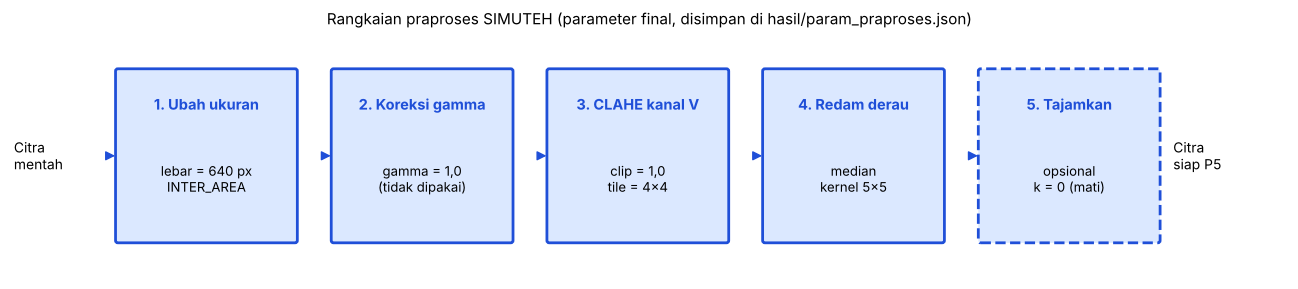

In [7]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
langkah = [("1. Ubah ukuran", "lebar = 640 px\nINTER_AREA", False),
           ("2. Koreksi gamma", "gamma = 1,0\n(tidak dipakai)", False),
           ("3. CLAHE kanal V", "clip = 1,0\ntile = 4x4", False),
           ("4. Redam derau", "median\nkernel 5x5", False),
           ("5. Tajamkan", "opsional\nk = 0 (mati)", True)]
fig, ax = plt.subplots(figsize=(16.5, 3.2)); ax.axis("off"); ax.set_xlim(0, 16.6); ax.set_ylim(0, 3.2)
ax.text(0.05, 1.6, "Citra\nmentah", fontsize=10, va="center")
for i, (j, d, opsi) in enumerate(langkah):
    x = 1.4 + i * 2.8
    ax.add_patch(FancyBboxPatch((x, 0.5), 2.3, 2.2, boxstyle="round,pad=0.03", fc="#dbe8ff", ec="#1f4fd8", lw=2, ls="--" if opsi else "-"))
    ax.text(x + 1.15, 2.2, j, ha="center", fontsize=10.5, weight="bold", color="#1f4fd8")
    ax.text(x + 1.15, 1.3, d.replace("\\n", "\n"), ha="center", fontsize=9.5, va="center")
    ax.add_patch(FancyArrowPatch((x - 0.15, 1.6), (x, 1.6), arrowstyle="-|>", mutation_scale=14, color="#1f4fd8"))
ax.text(15.1, 1.6, "Citra\nsiap P5", fontsize=10, va="center", ha="left")
ax.set_title("Rangkaian praproses SIMUTEH (parameter final, disimpan di hasil/param_praproses.json)", fontsize=11)
plt.savefig("../hasil/b5_diagram_praproses.png", dpi=150, bbox_inches="tight")